# Decision Trees with SDSS Astronomical Data
## Can we classify stars, galaxies and quasars from their colours?

In this notebook we will use real **Sloan Digital Sky Survey (SDSS)** data.

Our catalogue contains three spectroscopically identified classes:

- **STAR**
- **GALAXY**
- **QSO** — quasar

For each object we have its position on the sky, its brightness through the five SDSS filters, and its spectroscopic redshift.

We will train a **decision tree** to predict the astronomical class using only photometric colours.

This is **supervised machine learning** because the training data already contains the correct class.

### What you will learn

1. Load or create an astronomical catalogue
2. Explore SDSS photometry
3. Calculate astronomical colours
4. Split data into training and testing samples
5. Train a decision tree
6. Make predictions
7. Measure its performance
8. Draw the tree and inspect the rules it learned
9. Investigate the model's mistakes

## 1. Import packages

In [1]:
from pathlib import Path
from urllib.parse import urlencode

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

# 2. Get the data

This notebook can work in **two ways**.

### Option A — use a prepared file

If you already have:

`sdss_decision_tree.csv`

put it in the **same folder as this notebook**.

The notebook will simply load it.

### Option B — create the file from SDSS

If the file is not present, the next cell will query the SDSS SkyServer database for:

- 1000 stars
- 1000 galaxies
- 1000 quasars

It will then save the result as:

`sdss_decision_tree.csv`

You only need to download the data once.

In [93]:
DATA_FILE = Path("sdss_5000_decision_tree.csv")

if DATA_FILE.exists():

    print("Found sdss_decision_tree.csv")
    print("Loading saved data...")

    data = pd.read_csv(DATA_FILE)

else:

    print("sdss_decision_tree.csv not found.")
    print("Downloading data from SDSS...")
    print()

    base_url = "https://skyserver.sdss.org/dr18/SkyServerWS/SearchTools/SqlSearch"

    classes = ["STAR", "GALAXY", "QSO"]

    all_data = []

    for object_class in classes:

        print(f"Downloading {object_class}...")

        query = f"""
        SELECT TOP 5000
            ra,
            dec,
            modelmag_u,
            modelmag_g,
            modelmag_r,
            modelmag_i,
            modelmag_z,
            z AS redshift
        FROM SpecPhoto
        WHERE class = '{object_class}'
            AND zWarning = 0
        """

        params = urlencode({
            "cmd": " ".join(query.split()),
            "format": "csv"
        })

        url = base_url + "?" + params

        # SDSS puts "#Table1" on the first line,
        # so skip that line when reading the CSV.
        df = pd.read_csv(url, skiprows=1)

        # Give the magnitude columns simpler names
        df = df.rename(columns={
            "modelmag_u": "u",
            "modelmag_g": "g",
            "modelmag_r": "r",
            "modelmag_i": "i",
            "modelmag_z": "z"
        })

        # Add the known class
        df["class"] = object_class

        print(f"Downloaded {len(df)} objects")
        print(df.columns.tolist())
        print()

        all_data.append(df)


    # Combine the three samples
    data = pd.concat(
        all_data,
        ignore_index=True
    )


    # Keep the columns we want
    data = data[
        [
            "ra",
            "dec",
            "u",
            "g",
            "r",
            "i",
            "z",
            "redshift",
            "class"
        ]
    ]


    # Save the catalogue
    data.to_csv(
        DATA_FILE,
        index=False
    )

    print("Download complete!")
    print(f"Saved as: {DATA_FILE}")


# Check the final dataset
print()
print("Total objects:", len(data))

print()
print("Columns:")
print(data.columns.tolist())

print()
print("Objects in each class:")
print(data["class"].value_counts())

display(data.head())

sdss_decision_tree.csv not found.

Downloaded 5000 objects
['ra', 'dec', 'u', 'g', 'r', 'i', 'z', 'redshift', 'class']

Downloaded 5000 objects
['ra', 'dec', 'u', 'g', 'r', 'i', 'z', 'redshift', 'class']

Downloaded 5000 objects
['ra', 'dec', 'u', 'g', 'r', 'i', 'z', 'redshift', 'class']

Download complete!
Saved as: sdss_5000_decision_tree.csv

Total objects: 15000

Columns:
['ra', 'dec', 'u', 'g', 'r', 'i', 'z', 'redshift', 'class']

Objects in each class:
class
STAR      5000
GALAXY    5000
QSO       5000
Name: count, dtype: int64


,ra,dec,u,g,r,i,z,redshift,class
0,145.28112,-0.330472,19.36548,18.94647,19.04925,19.21883,19.35806,0.000111,STAR
1,145.28412,0.706299,20.36442,18.21354,17.38881,17.11562,17.32000,0.000178,STAR
2,145.29280,0.376335,19.31302,18.13527,17.67289,17.49996,17.44187,0.000213,STAR
3,145.26257,0.310931,24.85999,20.76403,19.18368,17.93489,17.28289,0.000066,STAR
4,145.73040,1.164938,18.32052,17.01957,16.47373,16.26664,16.14915,0.000286,STAR


In [109]:
before = len(data)

# Keep only objects where ALL five magnitudes
# are between 10 and 30
good_data = (
    (data["u"].between(10, 30)) &
    (data["g"].between(10, 30)) &
    (data["r"].between(10, 30)) &
    (data["i"].between(10, 30)) &
    (data["z"].between(10, 30))
)

data = data[good_data].copy()

after = len(data)

print("Objects before cleaning:", before)
print("Objects after cleaning:", after)
print("Objects removed:", before - after)

Objects before cleaning: 15000
Objects after cleaning: 14982
Objects removed: 18


## 3. Check the catalogue

Before doing any machine learning, always check what you actually loaded.

We expect these columns:

- `ra`, `dec` — position on the sky
- `u`, `g`, `r`, `i`, `z` — SDSS magnitudes
- `redshift` — spectroscopic redshift
- `class` — STAR, GALAXY or QSO

In [118]:
print("Columns:")
print(data.columns.tolist())

print()
print("Shape:")
print(data.shape)

print()
print("Objects in each class:")
print(data["class"].value_counts())

display(data.head())

Columns:
['ra', 'dec', 'u', 'g', 'r', 'i', 'z', 'redshift', 'class', 'u-g', 'g-r', 'r-i', 'i-z']

Shape:
(14982, 13)

Objects in each class:
class
STAR      4996
GALAXY    4993
QSO       4993
Name: count, dtype: int64


,ra,dec,u,g,r,i,z,redshift,class,u-g,g-r,r-i,i-z
0,145.28112,-0.330472,19.36548,18.94647,19.04925,19.21883,19.35806,0.000111,STAR,0.41901,-0.10278,-0.16958,-0.13923
1,145.28412,0.706299,20.36442,18.21354,17.38881,17.11562,17.32000,0.000178,STAR,2.15088,0.82473,0.27319,-0.20438
2,145.29280,0.376335,19.31302,18.13527,17.67289,17.49996,17.44187,0.000213,STAR,1.17775,0.46238,0.17293,0.05809
3,145.26257,0.310931,24.85999,20.76403,19.18368,17.93489,17.28289,0.000066,STAR,4.09596,1.58035,1.24879,0.65200
4,145.73040,1.164938,18.32052,17.01957,16.47373,16.26664,16.14915,0.000286,STAR,1.30095,0.54584,0.20709,0.11749


## 4. Look at the photometry

SDSS observes through five filters:

**u → g → r → i → z**

These cover progressively longer wavelengths.

Let's look at the distribution of magnitudes.

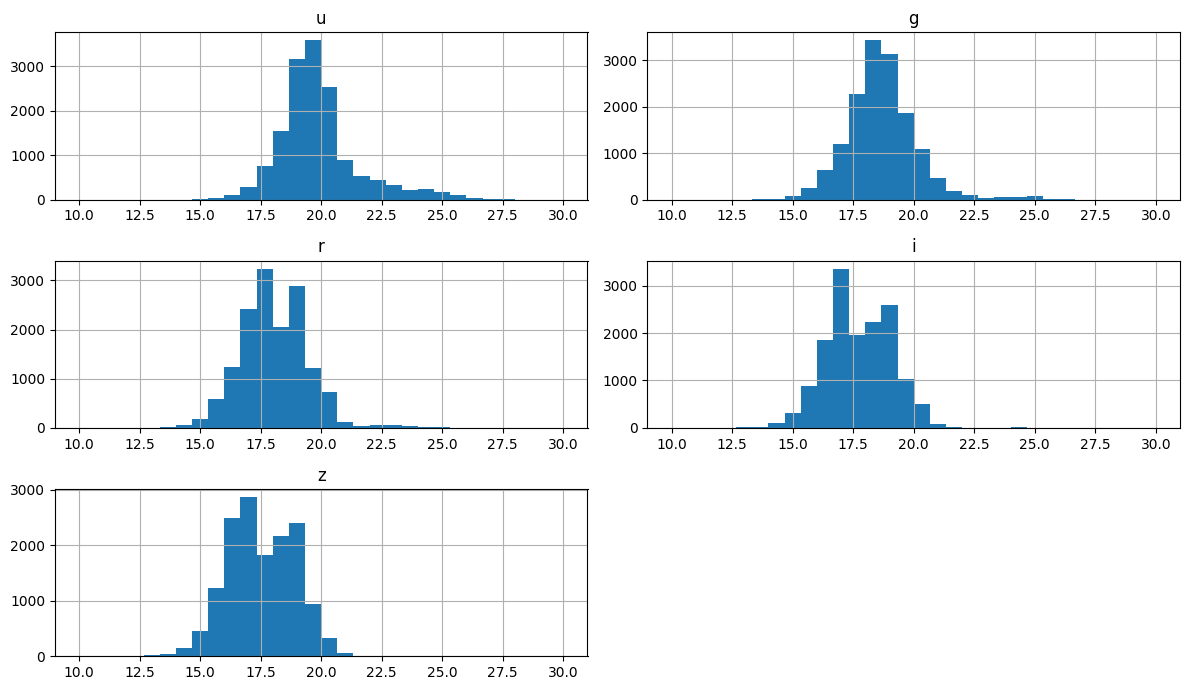

In [119]:
axes = data[["u", "g", "r", "i", "z"]].hist(
    figsize=(12, 7),
    bins=30,
    range=(10, 30)
)

plt.tight_layout()
plt.show()

# 5. Calculate astronomical colours

Astronomers often compare brightness between filters using **colours**.

A colour is simply the difference between two magnitudes.

For example:

`u - g = u magnitude - g magnitude`

We will calculate four colours.

In [120]:
data["u-g"] = data["u"] - data["g"]
data["g-r"] = data["g"] - data["r"]
data["r-i"] = data["r"] - data["i"]
data["i-z"] = data["i"] - data["z"]

display(
    data[
        ["u", "g", "r", "i", "z",
         "u-g", "g-r", "r-i", "i-z",
         "class"]
    ].head()
)

,u,g,r,i,z,u-g,g-r,r-i,i-z,class
0,19.36548,18.94647,19.04925,19.21883,19.35806,0.41901,-0.10278,-0.16958,-0.13923,STAR
1,20.36442,18.21354,17.38881,17.11562,17.32000,2.15088,0.82473,0.27319,-0.20438,STAR
2,19.31302,18.13527,17.67289,17.49996,17.44187,1.17775,0.46238,0.17293,0.05809,STAR
3,24.85999,20.76403,19.18368,17.93489,17.28289,4.09596,1.58035,1.24879,0.65200,STAR
4,18.32052,17.01957,16.47373,16.26664,16.14915,1.30095,0.54584,0.20709,0.11749,STAR


## 6. Look at the astronomy first

Before fitting a machine-learning model, let's look at the data ourselves.

We can plot:

`u-g` versus `g-r`

and colour the points using their known astronomical class.

Do stars, galaxies and quasars occupy different parts of colour space?

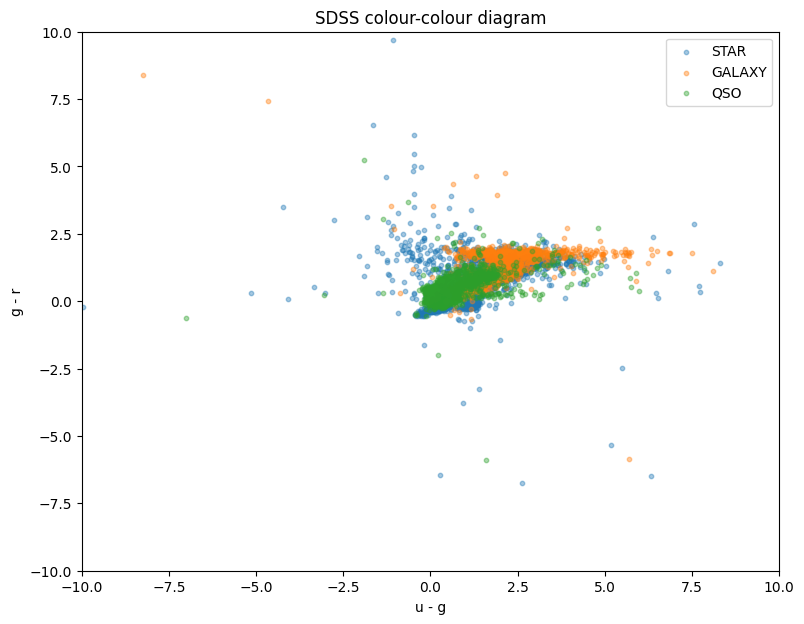

In [121]:
plt.figure(figsize=(9, 7))

for object_class in ["STAR", "GALAXY", "QSO"]:

    subset = data[data["class"] == object_class]

    plt.scatter(
        subset["u-g"],
        subset["g-r"],
        s=10,
        alpha=0.4,
        label=object_class
    )

plt.xlabel("u - g")
plt.ylabel("g - r")
plt.xlim([-10, 10])
plt.ylim([-10, 10])
plt.title("SDSS colour-colour diagram")
plt.legend()
plt.show()

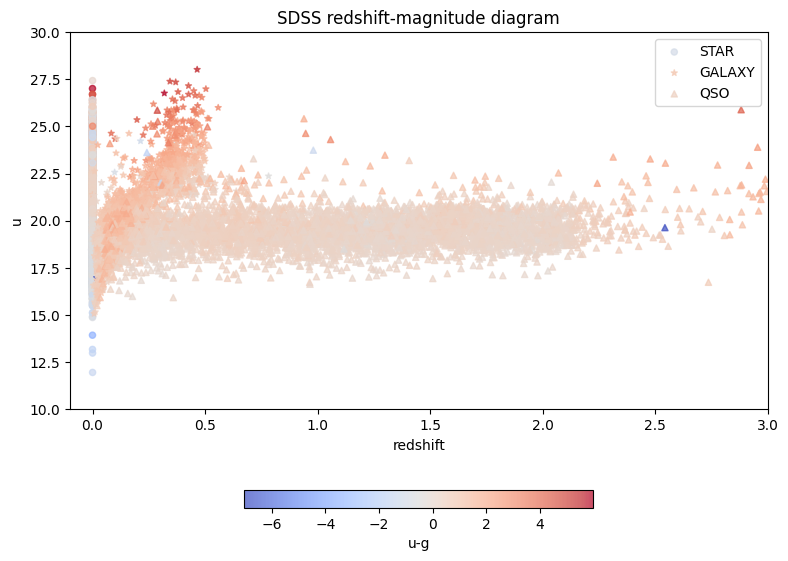

In [122]:
plt.figure(figsize=(9, 7))

markers = ['o', "*", '^']

for (object_class, marker) in zip(["STAR", "GALAXY", "QSO"], markers):

    subset = data[data["class"] == object_class]

    plt.scatter(
        subset["redshift"],
        subset["u"],
        s=20,
        alpha=0.7,
        label=object_class,
        c = subset["u-g"],
        cmap = 'coolwarm',
        marker = marker
    )

plt.colorbar(label="u-g", orientation="horizontal", shrink = 0.5)  

plt.xlabel("redshift")
plt.ylabel("u")
plt.ylim([10, 30])
plt.xlim([-0.1, 3])
plt.title("SDSS redshift-magnitude diagram")
plt.legend()
plt.show()

# 7. Choose our features and labels

For supervised machine learning we usually call our inputs **X** and our answers **y**.

### X

The measurements we give the model:

- `u-g`
- `g-r`
- `r-i`
- `i-z`

### y

The answer we want the model to learn:

- STAR
- GALAXY
- QSO

In [ ]:
#features = ["u-g", "g-r", "r-i", "i-z", "redshift"]
features = ["u", "g", "r", ]

X = data[features]
y = data["class"]

display(X.head())

print()
display(y.head())

,u,g,r
0,19.36548,18.94647,19.04925
1,20.36442,18.21354,17.38881
2,19.31302,18.13527,17.67289
3,24.85999,20.76403,19.18368
4,18.32052,17.01957,16.47373


0    STAR
1    STAR
2    STAR
3    STAR
4    STAR
Name: class, dtype: object

# 8. Split the catalogue

We do not want to test the model using the same objects it learned from.

We will therefore use:

- **80%** for training
- **20%** for testing

The model never sees the test objects during training.

In [130]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training objects:", len(X_train))
print("Testing objects:", len(X_test))

Training objects: 11985
Testing objects: 2997


# 9. Build a decision tree

A decision tree is a supervised machine-learning model that makes predictions by asking a sequence of simple yes/no questions about the data.
You can think of it a little like a flowchart. The model starts with all of our astronomical objects together, then tries to find a question that best separates the different classes.

For example, it might ask:
Is u-g < 0.8?

Objects where the answer is yes go down one branch of the tree, while objects where the answer is no go down another. The model then asks another question, perhaps using g-r or r-i, and continues splitting the objects into smaller groups.
Importantly, we don't choose these questions ourselves. During training, the decision-tree algorithm searches through the features and possible dividing values to find splits that do the best job of separating our known classes: STAR, GALAXY and QSO.
Eventually, an object reaches the end of a branch, called a leaf. The tree then assigns it a predicted class based on the training objects that ended up in that leaf.
We start with a deliberately small tree:

`max_depth=3` means it can only make a few layers of decisions.

In [131]:
tree = DecisionTreeClassifier(
    max_depth=10,
    random_state=42
)

tree.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


# 10. Make predictions

Now give the model the objects it has never seen before.

In [132]:
predictions = tree.predict(X_test)

print(predictions[:20])

['GALAXY' 'GALAXY' 'QSO' 'STAR' 'QSO' 'GALAXY' 'STAR' 'QSO' 'GALAXY'
 'STAR' 'GALAXY' 'GALAXY' 'STAR' 'GALAXY' 'GALAXY' 'GALAXY' 'QSO' 'STAR'
 'QSO' 'QSO']


# 11. Measure the accuracy

In [133]:
accuracy = accuracy_score(y_test, predictions)

print(f"Accuracy = {accuracy:.3f}")
print(f"Correct = {accuracy * 100:.1f}%")

Accuracy = 0.825
Correct = 82.5%


# 12. Confusion matrix

Accuracy gives us one number.

A **confusion matrix** tells us which astronomical populations are being confused with one another.

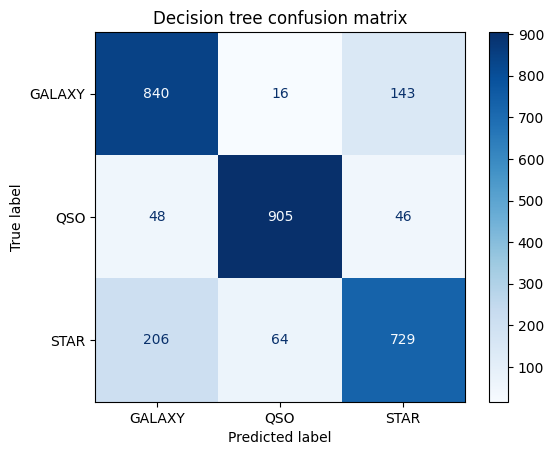

In [128]:
ConfusionMatrixDisplay.from_predictions(
    y_test,
    predictions,
    cmap="Blues"
)

plt.title("Decision tree confusion matrix")
plt.show()

# 13. Draw the decision tree

One advantage of decision trees is that we can actually see the rules the computer learned.

Each box contains a question about one of our astronomical colours.

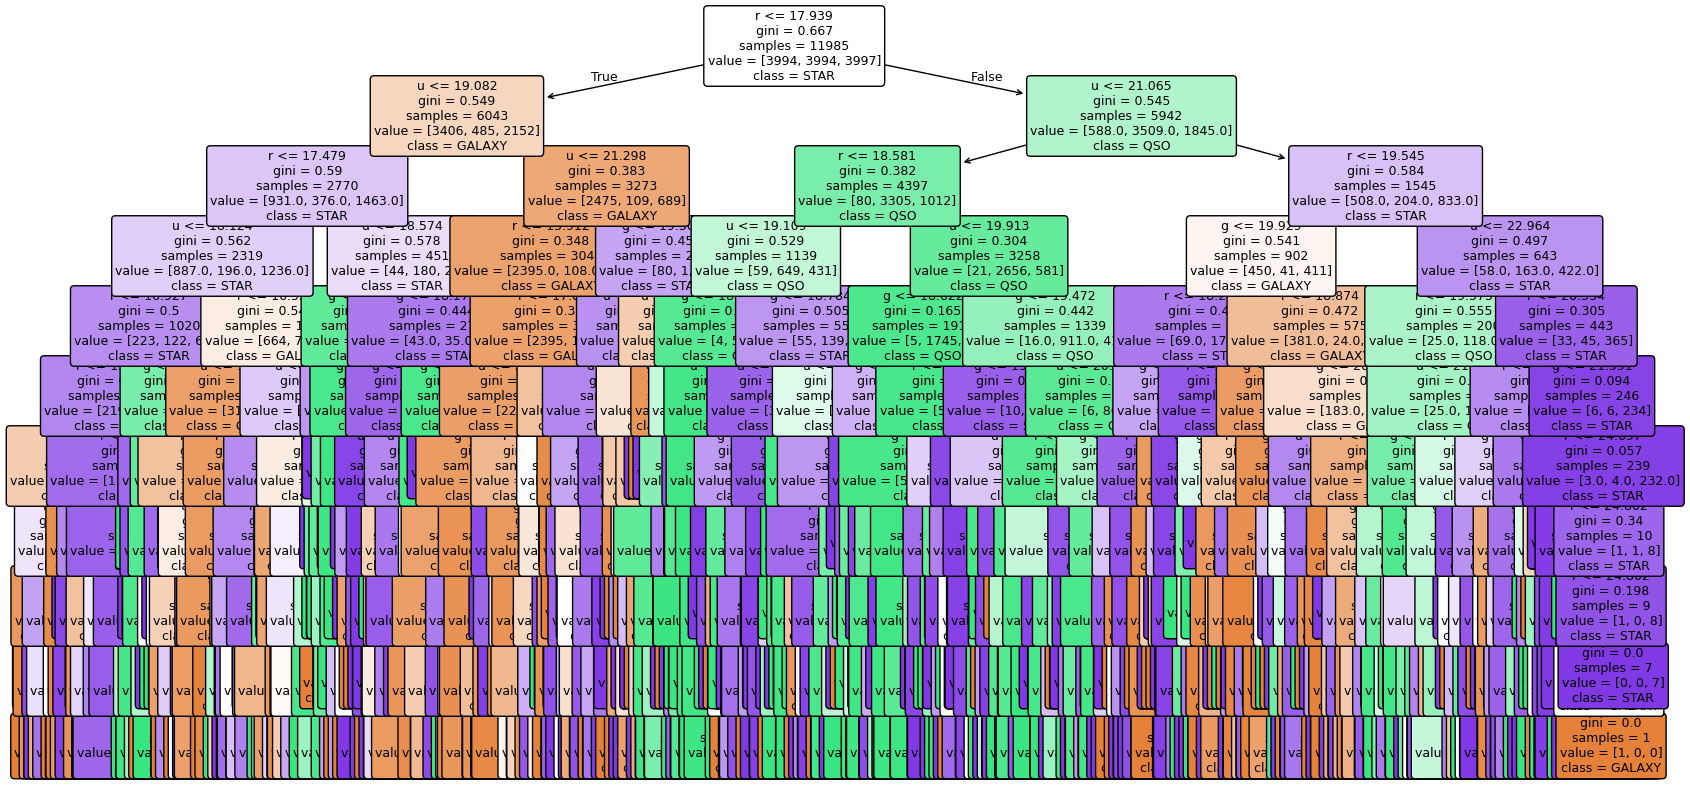

In [129]:
plt.figure(figsize=(20, 10))

plot_tree(
    tree,
    feature_names=features,
    class_names=tree.classes_,
    filled=True,
    rounded=True,
    fontsize=9
)

plt.show()

# 14. Which colours were most useful?

The decision tree can tell us which measurements it relied on most strongly.

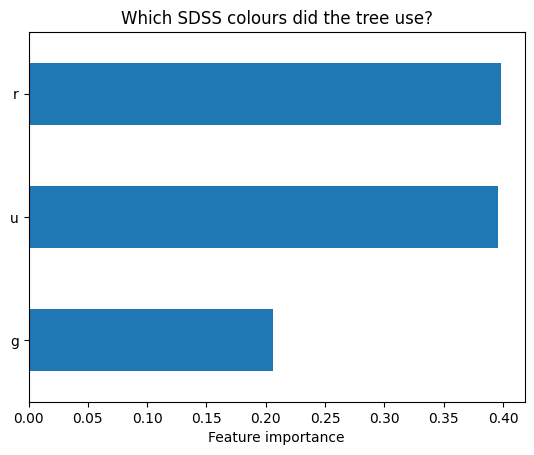

In [106]:
importance = pd.Series(
    tree.feature_importances_,
    index=features
).sort_values()

importance.plot(kind="barh")

plt.xlabel("Feature importance")
plt.title("Which SDSS colours did the tree use?")
plt.show()

# 15. Look at the mistakes

Machine-learning mistakes can often be more interesting than the correct classifications.

Let's find the objects where:

`prediction != true class`

In [107]:
results = X_test.copy()

results["true_class"] = y_test
results["prediction"] = predictions

wrong = results[
    results["true_class"] != results["prediction"]
]

print("Incorrect classifications:", len(wrong))

display(wrong.head(20))

Incorrect classifications: 474


,u,g,r,true_class,prediction
9341,-9999.00000,-9999.00000,-9999.00000,GALAXY,STAR
6852,17.94147,16.64837,15.99603,GALAXY,STAR
3810,20.47513,18.15374,17.23309,STAR,GALAXY
1709,18.82531,18.37890,18.50780,STAR,QSO
3448,22.24500,20.80972,20.25461,STAR,QSO
3695,18.34138,18.38044,18.66985,STAR,QSO
7427,23.16028,19.27848,17.59675,GALAXY,STAR
3911,17.96752,18.04781,18.30311,STAR,QSO
9784,21.74343,20.41155,19.67033,GALAXY,QSO
1145,19.14948,17.95711,17.45627,STAR,GALAXY


# 16. Plot the mistakes in colour space

This lets us see whether incorrectly classified objects sit near overlapping populations.

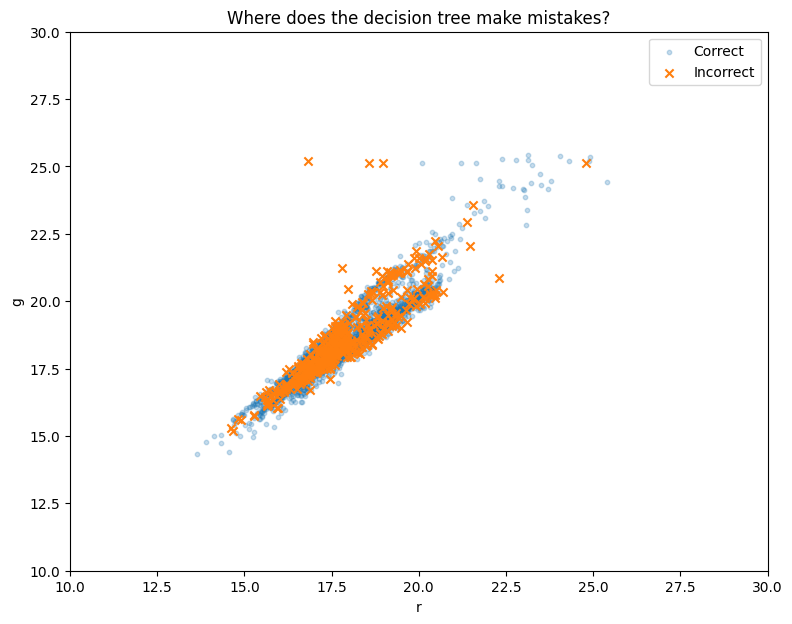

In [108]:
plt.figure(figsize=(9, 7))

correct = results[
    results["true_class"] == results["prediction"]
]

wrong = results[
    results["true_class"] != results["prediction"]
]

plt.scatter(
    correct["r"],
    correct["g"],
    s=10,
    alpha=0.25,
    label="Correct"
)

plt.scatter(
    wrong["r"],
    wrong["g"],
    s=35,
    marker="x",
    label="Incorrect"
)

plt.xlabel("r")
plt.ylabel("g")
plt.xlim([10, 30])
plt.ylim([10, 30])
plt.title("Where does the decision tree make mistakes?")
plt.legend()
plt.show()

# Your turn

## Exercise 1 — change the tree depth

Try:

```python
max_depth=1
```

then:

```python
max_depth=2
max_depth=5
max_depth=10
```

How does the accuracy change?

Can a decision tree become **too complicated**?

---

## Exercise 2 — use fewer colours

Try:

```python
features = ["u-g", "g-r"]
```

Retrain the model.

How much does the accuracy change?

---

## Exercise 3 — use magnitudes instead

Try:

```python
features = ["u", "g", "r", "i", "z"]
```

How does the result compare with using colours?

Why might colours contain useful information about the shape of an object's spectrum?

---

## Exercise 4 — investigate the confusion matrix

Which two astronomical classes are confused most often?

Look back at the colour-colour diagram.

Does their location in colour space help explain why?

---

## Exercise 5 — add redshift

So far we deliberately haven't used redshift.

Try:

```python
features = [
    "u-g",
    "g-r",
    "r-i",
    "i-z",
    "redshift"
]
```

What happens to the accuracy?

Then ask:

> Is this still the same scientific problem?

Remember that these redshifts came from spectroscopy.

# Take-home idea

A decision tree learns a sequence of simple rules from labelled examples.

In this example, the rules divide **astronomical colour space** into regions associated with stars, galaxies and quasars.

The model does not know what a star, galaxy or quasar physically is.

It only knows that certain combinations of measured colours were associated with particular labels in its training data.

That distinction — between **finding a statistical pattern** and **understanding the astrophysics behind it** — is important throughout machine learning.